# 1.Librerias y llamado de datos

In [169]:
import numpy as np
import pandas as pd
import sys
sys.path.append("..")  # codigo/, donde está inicio.py
from inicio import cargar
from sklearn.model_selection import train_test_split

#Pandas Options
pd.set_option('display.max_columns', 10000)
pd.set_option('display.max_colwidth', 100000)
pd.set_option('display.max_rows', 980000)


#Modelos de esamble
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.ensemble import HistGradientBoostingClassifier

#Manejo de graficas
import matplotlib.pyplot as plt
import seaborn as sns#Manejo de graficas
import matplotlib.pyplot as plt


#Librerias que usa el modelo de adri
import catboost
from catboost import CatBoostClassifier, Pool
from xgboost import XGBClassifier

#Modelo de reducción de dimensionalidad y selección de variables
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.preprocessing import StandardScaler

#Imputaciòn de variables

from sklearn.pipeline import Pipeline
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.preprocessing import StandardScaler

#variable de decisiòn
from sklearn.metrics import RocCurveDisplay, roc_auc_score, confusion_matrix

#### 1.1 LlAMADOS DE DATOS LIMPIOS, PREDICTORES Y VARIABLES OBJETIVO 

Se realiza el llamado de los datos para utilizarlos

* df: es el dataframe a usar
* PREDICTORES: variables predictoras a utilizar
* DESENLACES: variables objeivo
* particion_temporal: Es la columna que nos indica si el dato es de entrenamiento o prueba

In [170]:
df, PREDICTORES, DESENLACES = cargar()
df.sample(n = 5)

,record_id,sex,age,bmi,type_of_admission,ecog,shock,sepsis,lactate,excess base,bicarbonate,pafi,hemoglobin,leukocytes,neuthrophils,lymphocytes,platelet,pt,aptt,ast,alt,total_bilirubin,direct_bilirubin,indirect_bilirubin,creatinine,bun,potassium,sodium,calcium,apacheii,sapsiii,sofa,support renal,vasopressors_use,sedatives_use,painkillers_use,methylene_blue_use,delirium,mortality,Sequ_mol_fish_study,icu_readmission,origin_of_tumor,staging_risk,ventilatory_support,oncological_treatment,death_30d,fecha_ingreso,dias_estancia,mort_esperada_saps3,mort_esperada_apache,estancia_prolongada,muerte_o_estancia_prolongada,particion_temporal,muerte_uci_o_30d_post_egreso,mort_esperada_saps3_general,id_paciente_aprox,version_limpieza
913,914,2,35,31.833910,2.0,1.0,0,0,3.2,-2.5,20.0,268.0,13.8,23790.0,20750.0,1300.0,265000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.48,15.5,4.10,140.7,NaN,7.0,55.0,NaN,0.0,0,0,1,0,0,0,2.0,0.0,1,1.0,0,0,0.0,2022-09-20,1.0,25.70,7.620950,0.0,0,entrenamiento,0.0,25.71,839,v1.1
846,847,1,84,23.147255,1.0,2.0,1,1,3.3,-12.7,11.2,179.0,11.8,3360.0,2900.0,280.0,253000.0,NaN,NaN,17.9,12.9,0.26,0.19,0.07,3.92,82.9,4.76,132.0,NaN,17.0,68.0,6.0,0.0,1,1,1,1,0,0,NaN,0.0,1,NaN,1,0,0.0,2024-08-26,11.0,52.46,26.211596,1.0,1,prueba,0.0,52.46,128,v1.1
7,8,1,67,24.246777,1.0,2.0,1,1,4.4,-7.1,15.6,229.0,10.9,23570.0,20830.0,580.0,46000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.80,17.8,3.86,NaN,NaN,20.0,96.0,NaN,0.0,1,1,1,0,1,0,NaN,2.0,1,NaN,0,0,0.0,2023-02-25,9.0,89.10,35.503039,1.0,1,entrenamiento,0.0,89.14,267,v1.1
553,554,2,59,27.548209,2.0,3.0,1,1,NaN,NaN,NaN,NaN,9.2,10700.0,8620.0,930.0,183000.0,12.8,27.0,46.8,25.9,0.20,0.14,0.06,0.83,29.9,4.08,147.9,8.62,18.0,57.0,4.0,0.0,1,1,1,0,1,0,NaN,0.0,0,0.0,1,1,0.0,2024-04-08,40.0,29.00,29.131629,1.0,1,entrenamiento,0.0,29.52,791,v1.1
564,565,2,72,27.343750,1.0,0.0,0,0,NaN,NaN,NaN,NaN,15.6,8970.0,7750.0,970.0,428000.0,12.1,39.4,NaN,NaN,NaN,NaN,NaN,0.89,28.6,3.35,132.1,9.94,15.0,37.0,0.0,0.0,0,0,0,0,0,0,NaN,NaN,1,NaN,0,0,0.0,2023-11-28,2.0,4.53,20.965610,0.0,0,entrenamiento,0.0,4.53,760,v1.1


In [171]:
try:
    DESENLACES = list(DESENLACES.keys())
    DESENLACES[1]
except Exception as e:
    print(f"Error: {e}")


división datos de prueba y entrenamiento

In [172]:
df_prueba = df[df['particion_temporal']=='prueba']
df_entrenamiento = df[df['particion_temporal']=='entrenamiento']
print(f"Valores de prueba: {df_prueba['particion_temporal'].shape[0]}")
print(f"Valores de entrenamiento: {df_entrenamiento['particion_temporal'].shape[0]}")

Valores de prueba: 181
Valores de entrenamiento: 816


Utilizar unicamente las variables predictoras y las variables objetivo

In [173]:
#Entrenamiento de los datos
x_train = df_entrenamiento[PREDICTORES]
y_train_mortality = df_entrenamiento[DESENLACES[0]]
y_train_estancia = df_entrenamiento[DESENLACES[1]]

#Prueba de los datos
x_test = df_prueba[PREDICTORES]
y_test_mortality = df_prueba[DESENLACES[0]]
y_test_estancia = df_prueba[DESENLACES[1]]

# 2. Imputación de valores faltantes, Escalamiento de las variables

Se considera utilizar para esta fase una imputación

In [174]:
#Obtener solo los valores sin nulos de los datos de entrenamiento y prueba

def obtener_datos_completos(df_entrenamiento, df_prueba, PREDICTORES, DESENLACES):

        df_entrenamiento_completo = df_entrenamiento.dropna()
        df_prueba_completo = df_prueba.dropna()

        x_train = df_entrenamiento_completo[PREDICTORES]
        y_train_mortality = df_entrenamiento_completo[DESENLACES[0]]
        y_train_estancia = df_entrenamiento_completo[DESENLACES[1]]

        #Prueba de los datos
        x_test = df_prueba_completo[PREDICTORES]
        y_test_mortality = df_prueba_completo[DESENLACES[0]]
        y_test_estancia = df_prueba_completo[DESENLACES[1]]

        return x_train, y_train_mortality, y_train_estancia, x_test, y_test_mortality, y_test_estancia

x_train_completo, y_train_mortality_completo, y_train_estancia_completo, x_test_completo, y_test_mortality_completo, y_test_estancia_completo   = obtener_datos_completos(df_entrenamiento, df_prueba, PREDICTORES, DESENLACES)

In [175]:
#Tecnicas de preprocesamiento de datos Caso 2 Imputación KNN
preprocesamiento_kk_simple = Pipeline([
    ("imputacion_knn", KNNImputer(n_neighbors=5)),
    ("imputacion_media", SimpleImputer(strategy="mean")),
    ("escalado", StandardScaler())
])

In [176]:
x_train_kk = preprocesamiento_kk_simple.fit_transform(x_train)
x_test_kk = preprocesamiento_kk_simple.transform(x_test)

In [177]:
# Caso 3 Imputación KNN + Columna indicadora de faltante 

def imputacion_knn_indicador(x_train, x_test):
    x_train_knn_indix = x_train.copy()
    x_test_knn_indix = x_test.copy()

    for col in x_train_knn_indix.columns:
        x_train_knn_indix[col + '_missing'] = x_train_knn_indix[col].isna()
        x_test_knn_indix[col + '_missing'] = x_test_knn_indix[col].isna()

    x_train_knn_indix = preprocesamiento_kk_simple.fit_transform(x_train_knn_indix)
    x_test_knn_indix = preprocesamiento_kk_simple.transform(x_test_knn_indix)

    return x_train_knn_indix, x_test_knn_indix



x_train_knn_indix, x_test_knn_indix = imputacion_knn_indicador(x_train_completo, x_test_completo)

In [178]:
#Standar Scalar
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
x_train_completo_scaled = scaler.fit_transform(x_train_knn_indix)
x_test_completo_scaled = scaler.transform(x_test_knn_indix)

# 3.Modelos Machine Learnig

In [179]:
# Modelos de ensamble
cat = CatBoostClassifier()
xgb = XGBClassifier()
rf = RandomForestClassifier()
gb = GradientBoostingClassifier()
lr = LogisticRegression()
ada = AdaBoostClassifier()
et = ExtraTreesClassifier()
hgb = HistGradientBoostingClassifier()


# 4.Pipeline de uso

Modelo de pruebas 

* Transformaciones standar, log, raiz cuadrada, y yeo_johnson
* Modelos entrenados CatBoostClassifier, XGBClassifier, RandomForestClassifier, GradientBoostingClassifier, LogisticRegression, AdaBoostClassifier,  ExtraTreesClassifier y HistGradientBoostingClassifier
* Se uso el metodo AUROC

In [181]:
from sklearn.preprocessing import FunctionTransformer, PowerTransformer
from sklearn.compose import ColumnTransformer

class ModeloProcessor:

    METODOS = ("knn", "knn_indicador", "completos")
    TRANSFORMACIONES = ("standard", "log", "sqrt", "yeo_johnson")

    def __init__(self, x_train, x_test, y_train, y_test, modelos=None, transformacion="standard"):
        if transformacion not in self.TRANSFORMACIONES:
            raise ValueError(f"Transformación inválida. Use una de {self.TRANSFORMACIONES}")
        self.x_train = x_train
        self.x_test = x_test
        self.y_train = y_train
        self.y_test = y_test
        self.transformacion = transformacion
        self.modelos = modelos or {
            "cat": CatBoostClassifier(verbose=0),
            "xgb": XGBClassifier(),
            "rf": RandomForestClassifier(),
            "gb": GradientBoostingClassifier(),
            "lr": LogisticRegression(max_iter=1000),
            "ada": AdaBoostClassifier(),
            "et": ExtraTreesClassifier(),
            "hgb": HistGradientBoostingClassifier(),
        }
        self.x_train_proc = None
        self.x_test_proc = None
        self.y_train_proc = None
        self.y_test_proc = None

    def _alinear_objetivo(self, y_train, y_test):
        """Elimina filas con objetivo nulo."""
        return y_train.dropna(), y_test.dropna()

    @staticmethod
    def _columnas_binarias(x):
        """Columnas con a lo sumo 2 valores distintos (sin contar nulos)."""
        return [c for c in x.columns if x[c].dropna().nunique() <= 2]

    @staticmethod
    def _log_seguro(x):
        # Desplaza por el mínimo del lote para evitar valores <= 0
        return np.log1p(np.clip(x, 0, None))

    @staticmethod
    def _sqrt_seguro(x):
        return np.sqrt(np.clip(x, 0, None))

    def _transformador(self):
        if self.transformacion == "standard":
            return StandardScaler()
        if self.transformacion == "log":
            return Pipeline([
                ("log", FunctionTransformer(self._log_seguro, feature_names_out="one-to-one")),
                ("escalado", StandardScaler()),
            ])
        if self.transformacion == "sqrt":
            return Pipeline([
                ("sqrt", FunctionTransformer(self._sqrt_seguro, feature_names_out="one-to-one")),
                ("escalado", StandardScaler()),
            ])
        return PowerTransformer(method="yeo-johnson", standardize=True)

    def _escalador(self, x_train):
        """Aplica la transformación solo a columnas no binarias."""
        binarias = self._columnas_binarias(x_train)
        # Las columnas indicadoras también se consideran binarias
        binarias += [c for c in x_train.columns if str(c).endswith("_missing") and c not in binarias]
        no_binarias = [c for c in x_train.columns if c not in binarias]
        return ColumnTransformer(
            [("num", self._transformador(), no_binarias)],
            remainder="passthrough",
        )

    def limpiar(self, metodo):
        if metodo not in self.METODOS:
            raise ValueError(f"Método inválido. Use uno de {self.METODOS}")

        x_train = self.x_train.copy()
        x_test = self.x_test.copy()
        y_train = self.y_train.copy()
        y_test = self.y_test.copy()

        # Quitar filas con objetivo nulo
        x_train, y_train = x_train.loc[y_train.notna()], y_train.dropna()
        x_test, y_test = x_test.loc[y_test.notna()], y_test.dropna()

        if metodo == "completos":
            mask_tr = x_train.notna().all(axis=1)
            mask_te = x_test.notna().all(axis=1)
            x_train, y_train = x_train[mask_tr], y_train[mask_tr]
            x_test, y_test = x_test[mask_te], y_test[mask_te]
            pre_imputacion = []
        else:
            if metodo == "knn_indicador":
                cols_nulas = [c for c in x_train.columns if x_train[c].isna().any()]
                for col in cols_nulas:
                    x_train[col + "_missing"] = x_train[col].isna().astype(int)
                    x_test[col + "_missing"] = x_test[col].isna().astype(int)
            pre_imputacion = [
                ("imputacion_knn", KNNImputer(n_neighbors=5).set_output(transform="pandas")),
                ("imputacion_media", SimpleImputer(strategy="mean").set_output(transform="pandas")),
            ]

        # Las columnas binarias se detectan antes de imputar
        escalador = self._escalador(x_train)
        prep = Pipeline(pre_imputacion + [("transformacion", escalador)])

        self.x_train_proc = prep.fit_transform(x_train)
        self.x_test_proc = prep.transform(x_test)
        self.y_train_proc = y_train
        self.y_test_proc = y_test
        return self

    def ejecutar(self, metodo="knn", modelo="lr"):
        if modelo not in self.modelos:
            raise ValueError(f"Modelo inválido. Use uno de {list(self.modelos)}")
        self.limpiar(metodo)
        clf = self.modelos[modelo]
        clf.fit(self.x_train_proc, self.y_train_proc)
        proba = clf.predict_proba(self.x_test_proc)[:, 1]
        return roc_auc_score(self.y_test_proc, proba)


def pipeline_modelo(x_train, x_test, y_train, y_test, metodo="knn", modelo="lr", transformacion="standard"):
    return ModeloProcessor(
        x_train, x_test, y_train, y_test, transformacion=transformacion
    ).ejecutar(metodo, modelo)


# Ejemplo de uso
for t in ModeloProcessor.TRANSFORMACIONES:
    auroc = pipeline_modelo(x_train, x_test, y_train_mortality, y_test_mortality,
                            metodo="knn_indicador", modelo="rf", transformacion=t)
    print(f"AUROC ({t}):", auroc)

AUROC (standard): 0.9426751592356688
AUROC (log): 0.9485138004246285
AUROC (sqrt): 0.9389596602972399
AUROC (yeo_johnson): 0.9438694267515924


In [ ]:
transformaciones = ("standard", "log", "sqrt", "yeo_johnson")
modelos_a_evaluar = ["cat", "xgb", "rf", "gb", "lr", "ada", "et", "hgb"]
resultados_transformaciones = []

for transformacion in transformaciones:
    for nombre_objetivo, (ytr, yte) in objetivos.items():
        for metodo in ModeloProcessor.METODOS:
            for nombre_modelo in modelos_a_evaluar:
                try:
                    procesador = ModeloProcessor(
                        x_train,
                        x_test,
                        ytr,
                        yte,
                        transformacion=transformacion
                    )
                    auroc = procesador.ejecutar(
                        metodo=metodo,
                        modelo=nombre_modelo
                    )
                except Exception as e:
                    auroc = np.nan
                    print(
                        f"Error en {transformacion} | {nombre_objetivo} | "
                        f"{metodo} | {nombre_modelo}: {e}"
                    )

                resultados_transformaciones.append({
                    "transformacion": transformacion,
                    "objetivo": nombre_objetivo,
                    "imputacion": metodo,
                    "modelo": nombre_modelo,
                    "auroc": auroc,
                })

df_resultados_transformaciones = pd.DataFrame(resultados_transformaciones)


c:\Users\el_me\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
c:\Users\el_me\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
c:\Users\el_me\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
c:\Users\el_me\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
c:\Users\el_me\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_ra


AUROC — transformación: standard


c:\Users\el_me\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(


modelo                               ada    cat     et     gb    hgb     lr  \
objetivo            imputacion                                                
estancia_prolongada knn            0.888  0.899  0.898  0.897  0.901  0.884   
                    knn_indicador  0.899  0.907  0.890  0.886  0.903  0.875   
mortality           knn            0.923  0.927  0.930  0.944  0.926  0.899   
                    knn_indicador  0.935  0.938  0.921  0.947  0.924  0.906   

modelo                                rf    xgb  
objetivo            imputacion                   
estancia_prolongada knn            0.892  0.889  
                    knn_indicador  0.876  0.911  
mortality           knn            0.941  0.923  
                    knn_indicador  0.935  0.920


AUROC — transformación: log


modelo                               ada    cat     et     gb    hgb     lr  \
objetivo            imputacion                                                
estancia_prolongada knn            0.897  0.903  0.884  0.898  0.903  0.878   
                    knn_indicador  0.894  0.908  0.900  0.886  0.895  0.886   
mortality           knn            0.917  0.928  0.923  0.944  0.922  0.933   
                    knn_indicador  0.936  0.938  0.916  0.948  0.924  0.934   

modelo                                rf    xgb  
objetivo            imputacion                   
estancia_prolongada knn            0.902  0.891  
                    knn_indicador  0.897  0.899  
mortality           knn            0.937  0.915  
                    knn_indicador  0.936  0.914


AUROC — transformación: sqrt


modelo                               ada    cat     et     gb    hgb     lr  \
objetivo            imputacion                                                
estancia_prolongada knn            0.897  0.903  0.902  0.896  0.869  0.858   
                    knn_indicador  0.894  0.908  0.900  0.887  0.897  0.870   
mortality           knn            0.917  0.928  0.926  0.944  0.922  0.930   
                    knn_indicador  0.936  0.938  0.919  0.946  0.925  0.932   

modelo                                rf    xgb  
objetivo            imputacion                   
estancia_prolongada knn            0.893  0.891  
                    knn_indicador  0.876  0.899  
mortality           knn            0.949  0.915  
                    knn_indicador  0.945  0.914


AUROC — transformación: yeo_johnson


modelo                               ada    cat     et     gb    hgb     lr  \
objetivo            imputacion                                                
estancia_prolongada knn            0.888  0.899  0.883  0.901  0.890  0.911   
                    knn_indicador  0.899  0.907  0.893  0.884  0.895  0.907   
mortality           knn            0.923  0.927  0.930  0.940  0.925  0.894   
                    knn_indicador  0.935  0.938  0.919  0.937  0.926  0.908   

modelo                                rf    xgb  
objetivo            imputacion                   
estancia_prolongada knn            0.895  0.889  
                    knn_indicador  0.898  0.911  
mortality           knn            0.945  0.923  
                    knn_indicador  0.946  0.920

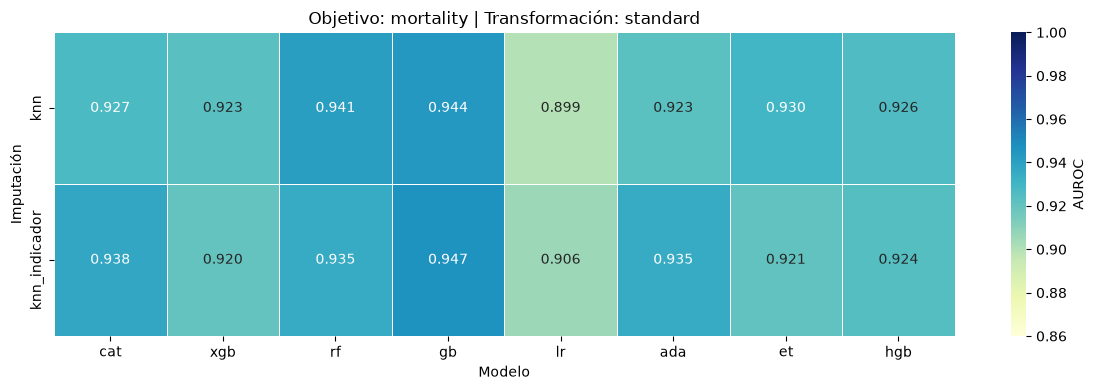

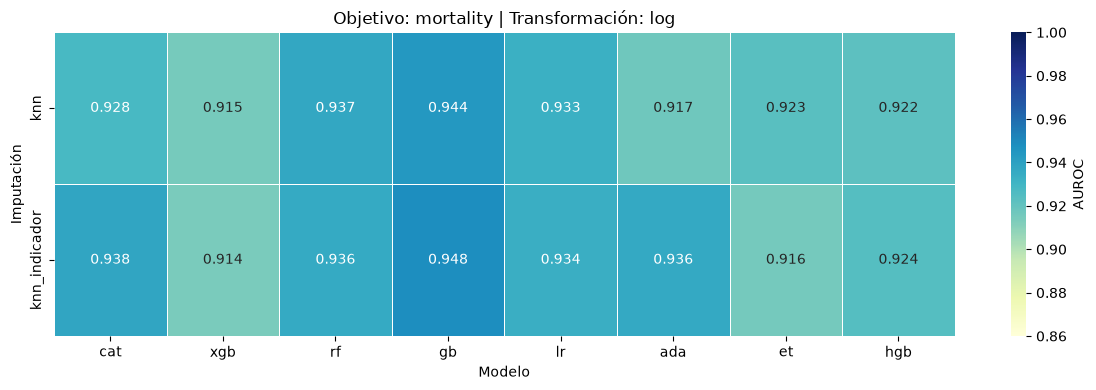

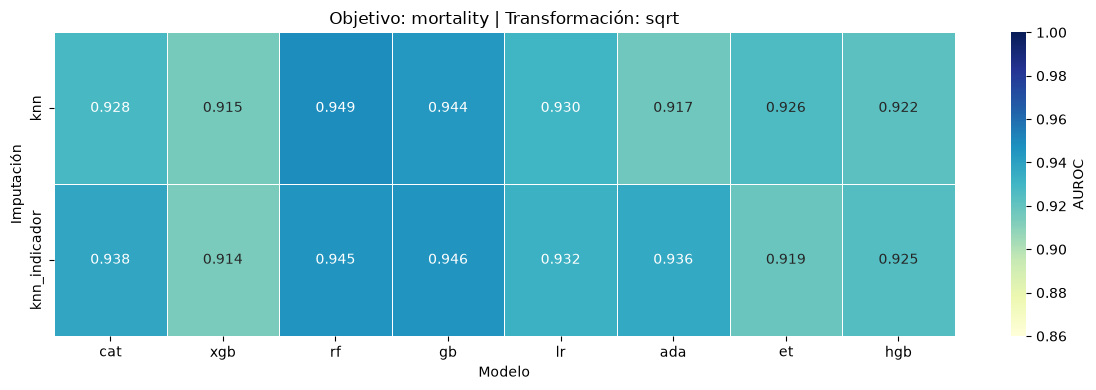

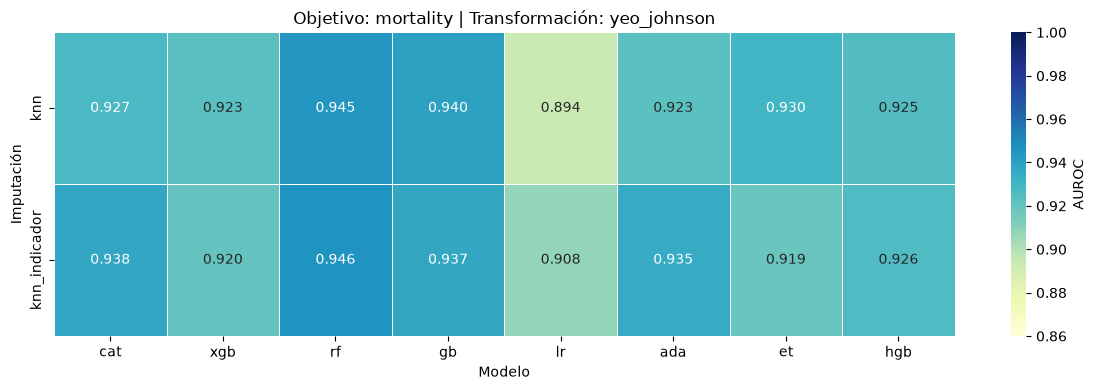

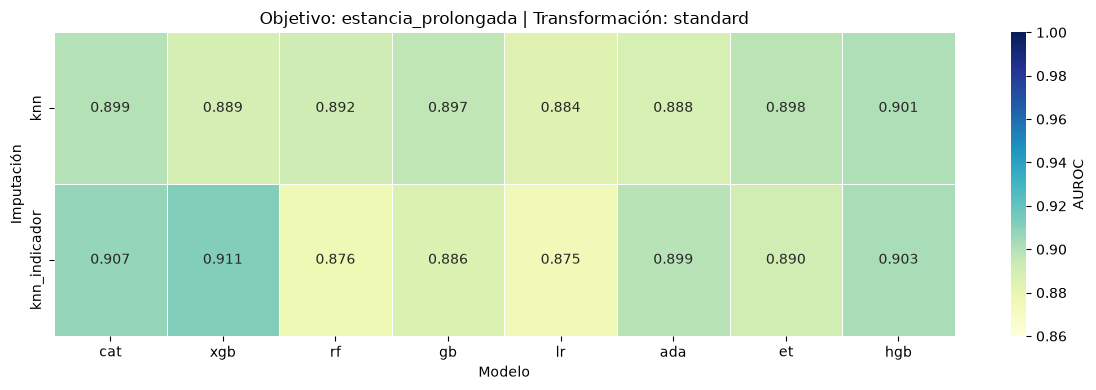

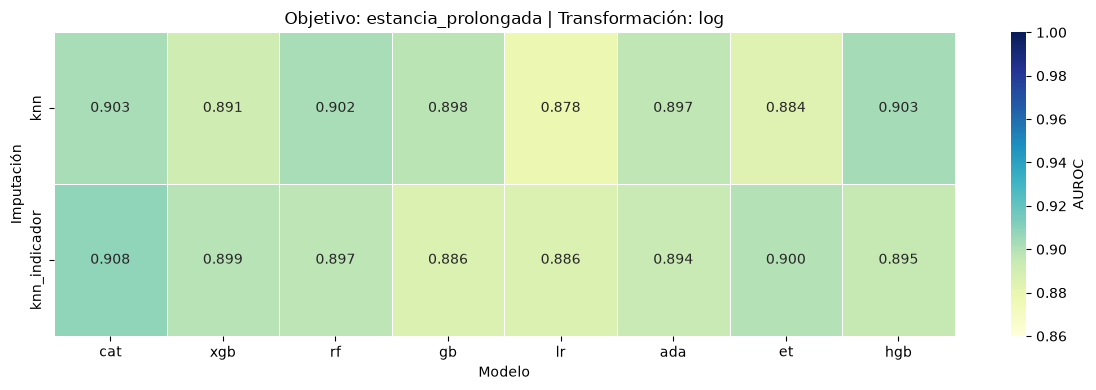

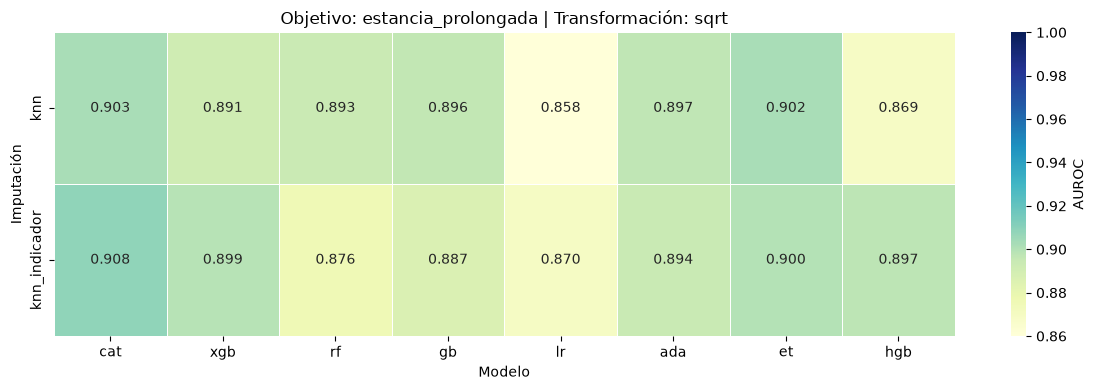

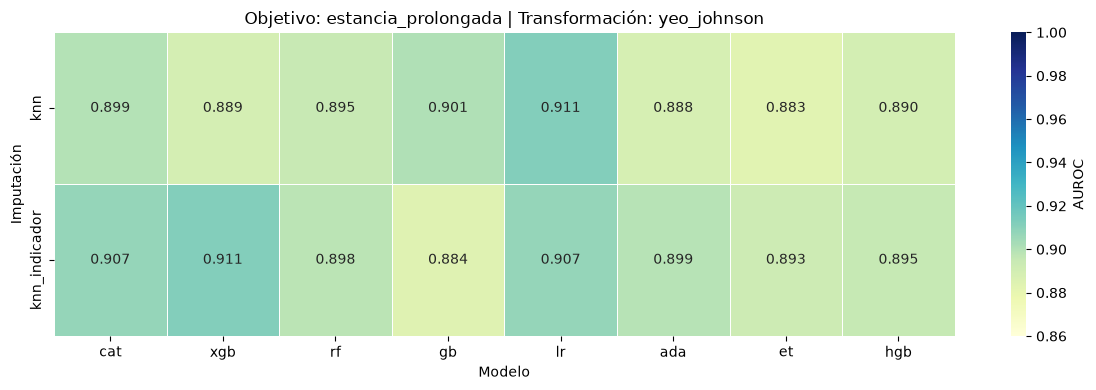

In [264]:
for objetivo in df_resultados_transformaciones["objetivo"].dropna().unique():
    for transformacion in transformaciones:
        datos = df_resultados_transformaciones[
            (df_resultados_transformaciones["objetivo"] == objetivo)
            & (df_resultados_transformaciones["transformacion"] == transformacion)
        ]

        tabla = datos.pivot_table(
            index="imputacion",
            columns="modelo",
            values="auroc"
        ).reindex(
            index=[metodo for metodo in ModeloProcessor.METODOS if metodo != "completos"],
            columns=modelos_a_evaluar
        )

        fig, ax = plt.subplots(figsize=(12, 4))
        ax.set_facecolor("lightgray")
        sns.heatmap(
            tabla, annot=True, fmt=".3f", cmap="YlGnBu",
            vmin=0.86, vmax=1, linewidths=0.5,
            cbar_kws={"label": "AUROC"}, ax=ax
        )

        for fila, columna in np.argwhere(tabla.isna().to_numpy()):
            ax.text(columna + 0.5, fila + 0.5, "N/D",
                    ha="center", va="center")

        ax.set_title(f"Objetivo: {objetivo} | Transformación: {transformacion}")
        ax.set_xlabel("Modelo")
        ax.set_ylabel("Imputación")
        plt.tight_layout()
        plt.show()

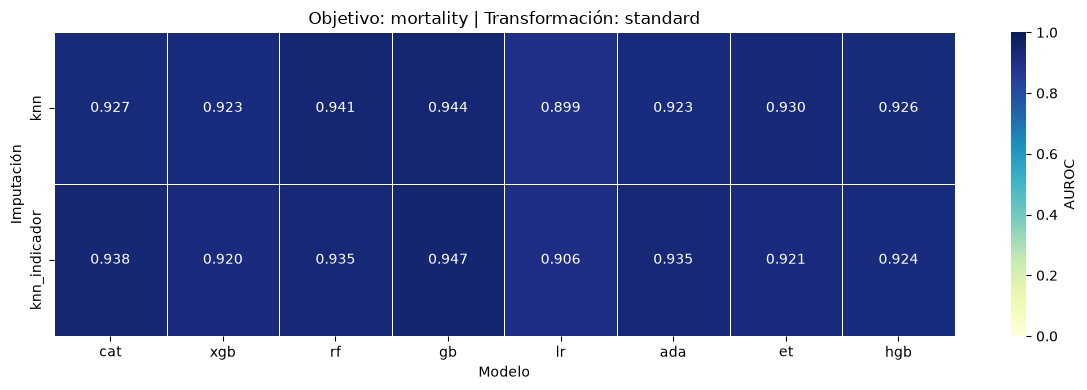

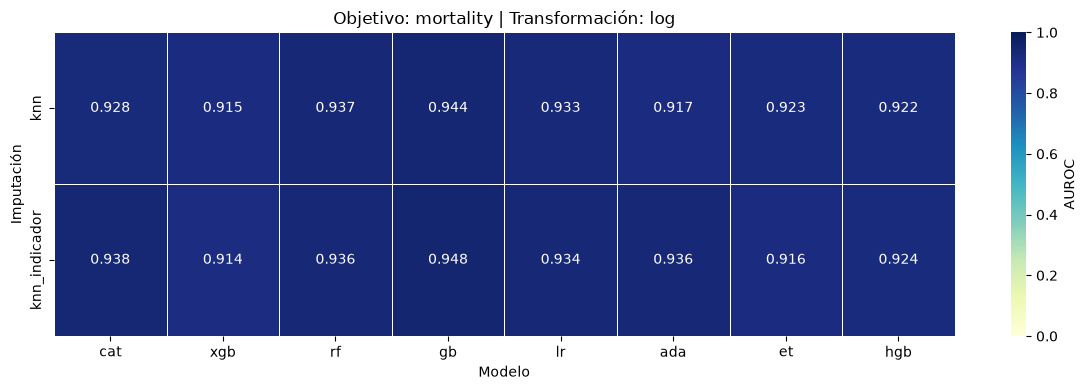

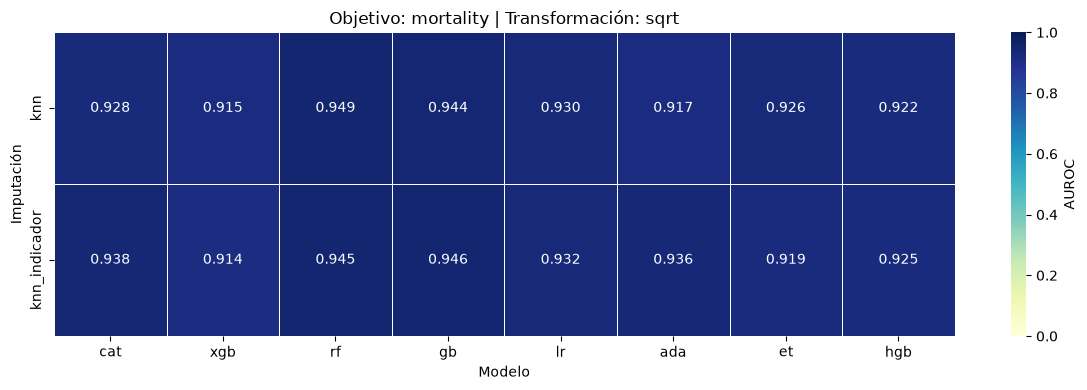

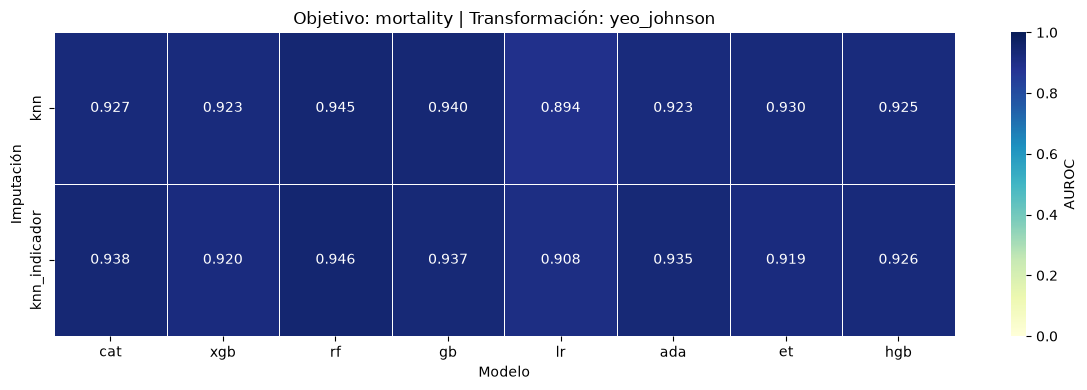

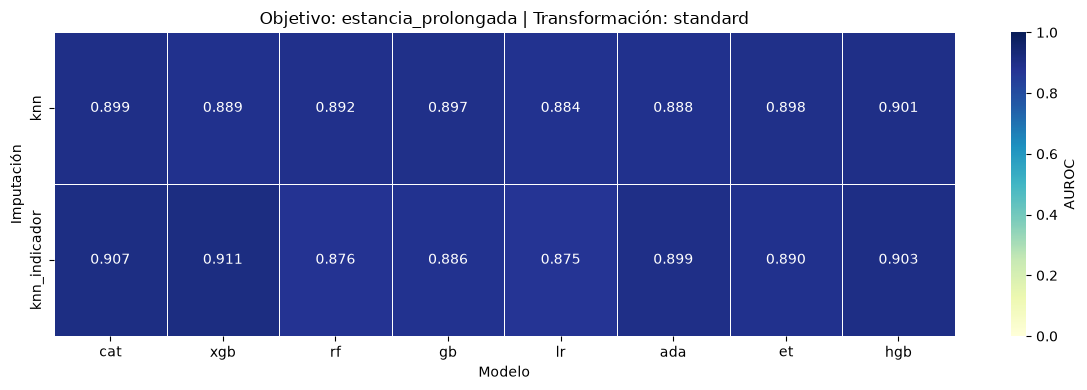

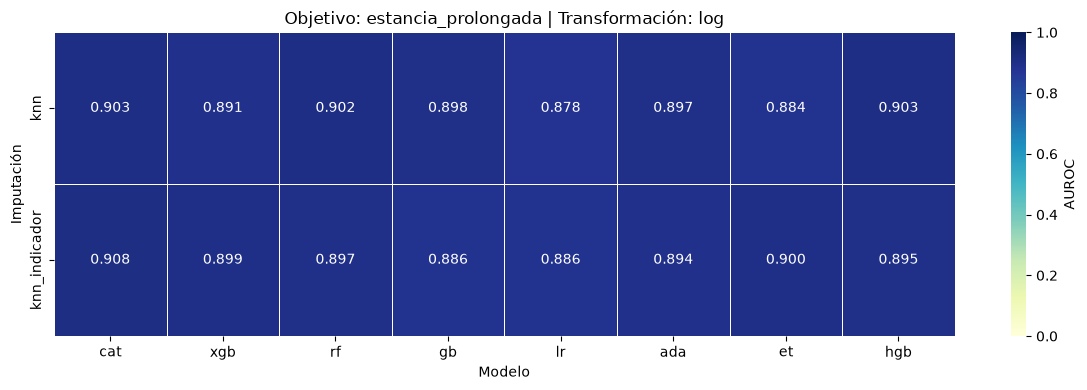

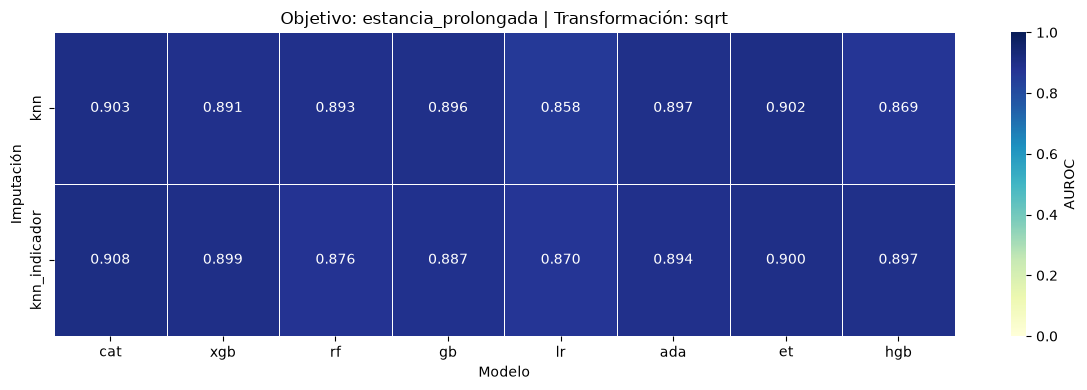

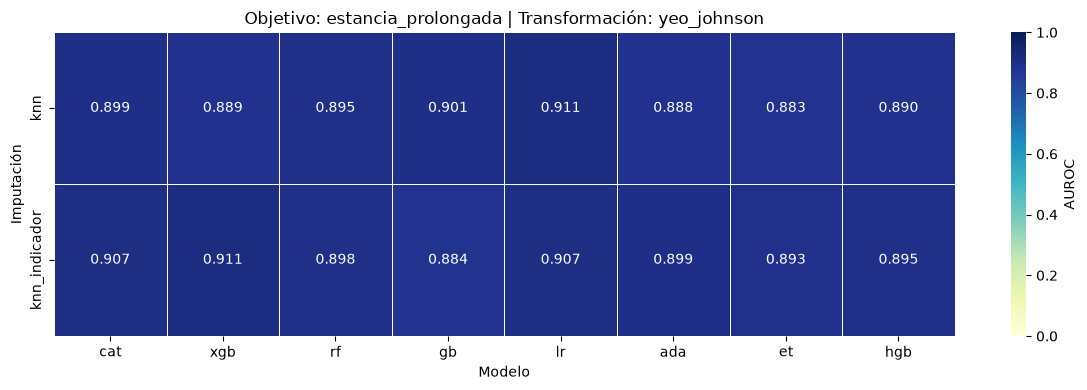

In [261]:
for objetivo in df_resultados_transformaciones["objetivo"].dropna().unique():
    for transformacion in transformaciones:
        datos = df_resultados_transformaciones[
            (df_resultados_transformaciones["objetivo"] == objetivo)
            & (df_resultados_transformaciones["transformacion"] == transformacion)
        ]

        tabla = datos.pivot_table(
            index="imputacion",
            columns="modelo",
            values="auroc"
        ).reindex(
            index=[metodo for metodo in ModeloProcessor.METODOS if metodo != "completos"],
            columns=modelos_a_evaluar
        )

        fig, ax = plt.subplots(figsize=(12, 4))
        ax.set_facecolor("lightgray")
        sns.heatmap(
            tabla, annot=True, fmt=".3f", cmap="YlGnBu",
            vmin=0, vmax=1, linewidths=0.5,
            cbar_kws={"label": "AUROC"}, ax=ax
        )

        for fila, columna in np.argwhere(tabla.isna().to_numpy()):
            ax.text(columna + 0.5, fila + 0.5, "N/D",
                    ha="center", va="center")

        ax.set_title(f"Objetivo: {objetivo} | Transformación: {transformacion}")
        ax.set_xlabel("Modelo")
        ax.set_ylabel("Imputación")
        plt.tight_layout()
        plt.show()

# 5. Evaluación de las variables mas relevantes PCA - SHAPLEY values. 

In [271]:
def tabla_pca_mortality(n_componentes=10, n_variables=10):
    mask_train = y_train_mortality.notna()
    mask_test = y_test_mortality.notna()

    prep = Pipeline([
        ("knn", KNNImputer(n_neighbors=5)),
        ("transformacion", PowerTransformer(method="yeo-johnson")),
    ])
    xtr = prep.fit_transform(x_train.loc[mask_train])
    xte = prep.transform(x_test.loc[mask_test])
    nombres = prep.named_steps["knn"].get_feature_names_out(x_train.columns)

    if not 1 <= n_componentes <= min(xtr.shape):
        raise ValueError("Número de componentes fuera del rango permitido.")
    if not 1 <= n_variables <= len(nombres):
        raise ValueError("Número de variables fuera del rango permitido.")

    pca_mortality = PCA(n_components=n_componentes)
    componentes_train = pca_mortality.fit_transform(xtr)
    componentes_test = pca_mortality.transform(xte)

    rf_mortality = RandomForestClassifier(random_state=0, verbose=0)
    rf_mortality.fit(componentes_train, y_train_mortality.loc[mask_train])

    filas = []
    for i, cargas in enumerate(pca_mortality.components_):
        indices = np.argsort(np.abs(cargas))[::-1][:n_variables]
        fila = {
            "componente": f"PC{i + 1}",
            "varianza_explicada_%": 100 * pca_mortality.explained_variance_ratio_[i],
            "importancia_rf": rf_mortality.feature_importances_[i],
        }
        for posicion, indice in enumerate(indices, start=1):
            fila[f"variable_{posicion}"] = f"{nombres[indice]} ({cargas[indice]:+.3f})"
        filas.append(fila)

    if y_test_mortality.loc[mask_test].nunique() == 2:
        proba = rf_mortality.predict_proba(componentes_test)[:, 1]
        print(f"AUROC: {roc_auc_score(y_test_mortality.loc[mask_test], proba):.3f}")

    return pd.DataFrame(filas)

tabla_componentes = tabla_pca_mortality(n_componentes=5, n_variables=5)
display(tabla_componentes.round(3))

AUROC: 0.918


,componente,varianza_explicada_%,importancia_rf,variable_1,variable_2,variable_3,variable_4,variable_5
0,PC1,14.987,0.326,sapsiii (+0.296),sepsis (+0.271),platelet (-0.257),hemoglobin (-0.244),type_of_admission (-0.234)
1,PC2,9.304,0.141,total_bilirubin (+0.469),direct_bilirubin (+0.464),indirect_bilirubin (+0.449),ast (+0.339),alt (+0.338)
2,PC3,7.856,0.206,leukocytes (+0.368),neuthrophils (+0.366),potassium (+0.313),bun (+0.271),creatinine (+0.244)
3,PC4,6.098,0.143,bicarbonate (+0.503),excess base (+0.501),pafi (-0.388),age (+0.223),type_of_admission (-0.183)
4,PC5,4.552,0.185,vasopressors_use (+0.433),shock (+0.373),creatinine (-0.339),bun (-0.315),ventilatory_support (+0.282)


In [272]:
tabla_componentes.to_excel(
    "H1_PCA_mortalidad.xlsx",
    index=False
)

In [283]:
def tabla_pca(y_train_obj, y_test_obj, n_componentes=5, n_variables=5, modelo=None):
    mask_train = y_train_obj.notna()
    mask_test = y_test_obj.notna()

    prep = Pipeline([
        ("knn", KNNImputer(n_neighbors=5)),
        ("media", SimpleImputer(strategy="mean")),
        ("escalado", StandardScaler()),
    ])
    xtr = prep.fit_transform(x_train.loc[mask_train])
    xte = prep.transform(x_test.loc[mask_test])
    nombres = np.array(x_train.columns)[:xtr.shape[1]]

    if not 1 <= n_componentes <= min(xtr.shape):
        raise ValueError("Número de componentes fuera del rango permitido.")
    if not 1 <= n_variables <= len(nombres):
        raise ValueError("Número de variables fuera del rango permitido.")

    pca_obj = PCA(n_components=n_componentes)
    componentes_train = pca_obj.fit_transform(xtr)
    componentes_test = pca_obj.transform(xte)

    modelo = modelo or XGBClassifier(random_state=0, verbosity=0)
    modelo.fit(componentes_train, y_train_obj.loc[mask_train])

    filas = []
    for i, cargas in enumerate(pca_obj.components_):
        indices = np.argsort(np.abs(cargas))[::-1][:n_variables]
        fila = {
            "componente": f"PC{i + 1}",
            "varianza_explicada_%": 100 * pca_obj.explained_variance_ratio_[i],
            "importancia_modelo": modelo.feature_importances_[i],
        }
        for posicion, indice in enumerate(indices, start=1):
            fila[f"variable_{posicion}"] = f"{nombres[indice]} ({cargas[indice]:+.3f})"
        filas.append(fila)

    y_te = y_test_obj.loc[mask_test]
    if y_te.nunique() == 2:
        proba = modelo.predict_proba(componentes_test)[:, 1]
        print(f"AUROC: {roc_auc_score(y_te, proba):.3f}")

    return pd.DataFrame(filas)


# Estancia prolongada
tabla_componentes_estancia = tabla_pca(y_train_estancia, y_test_estancia, n_componentes=5, n_variables=8)
display(tabla_componentes_estancia.round(3))

AUROC: 0.792


,componente,varianza_explicada_%,importancia_modelo,variable_1,variable_2,variable_3,variable_4,variable_5,variable_6,variable_7,variable_8
0,PC1,13.907,0.266,sapsiii (+0.321),sepsis (+0.275),sofa (+0.267),shock (+0.262),apacheii (+0.260),type_of_admission (-0.234),vasopressors_use (+0.224),bun (+0.223)
1,PC2,7.671,0.228,indirect_bilirubin (+0.428),direct_bilirubin (+0.414),total_bilirubin (+0.375),alt (+0.357),ast (+0.355),type_of_admission (+0.158),origin_of_tumor (+0.151),pafi (+0.139)
2,PC3,6.527,0.153,excess base (+0.403),bicarbonate (+0.380),potassium (-0.343),neuthrophils (-0.257),creatinine (-0.245),bun (-0.232),pafi (-0.231),leukocytes (-0.195)
3,PC4,6.101,0.187,leukocytes (+0.410),bicarbonate (+0.349),neuthrophils (+0.334),excess base (+0.318),pafi (-0.308),lymphocytes (+0.273),platelet (+0.203),age (+0.197)
4,PC5,5.182,0.166,lymphocytes (+0.453),leukocytes (+0.427),creatinine (-0.285),age (-0.246),potassium (-0.245),bun (-0.241),shock (+0.222),vasopressors_use (+0.216)


In [284]:
tabla_componentes_estancia['varianza_explicada_%'].sum()

np.float64(39.38723002320071)

In [274]:
tabla_componentes_estancia.to_excel(
    "H2_PCA_estancia.xlsx",
    index=False)

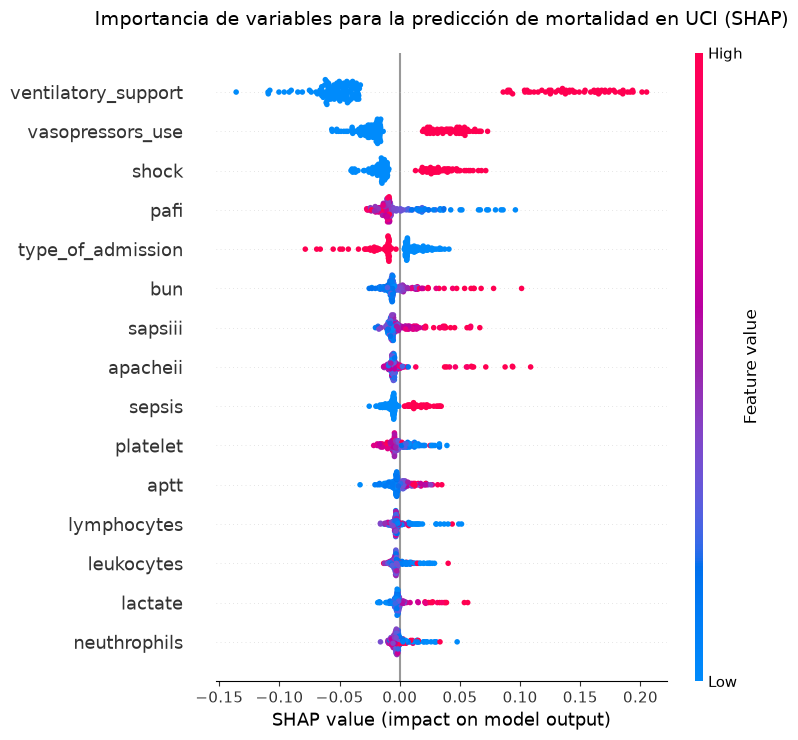

,importancia_media_absoluta_SHAP
ventilatory_support,0.083681
vasopressors_use,0.032646
shock,0.023922
pafi,0.016690
type_of_admission,0.015044
bun,0.011399
sapsiii,0.010698
apacheii,0.010207
sepsis,0.010038
platelet,0.007984


In [285]:
import shap

# Excluir filas sin variable objetivo
mask_train = y_train_mortality.notna()
mask_test = y_test_mortality.notna()

X_train = x_train.loc[mask_train]
y_train = y_train_mortality.loc[mask_train]
X_test = x_test.loc[mask_test]

# Preprocesamiento KNN ajustado solo con entrenamiento
prep_shap = Pipeline([
    ("knn", KNNImputer(n_neighbors=5)),
    ("media", SimpleImputer(strategy="mean")),
    ("escalado", StandardScaler()),
])

X_train_proc = prep_shap.fit_transform(X_train)
X_test_proc = prep_shap.transform(X_test)

# Nombres de variables tras el preprocesamiento
try:
    nombres_variables = prep_shap.get_feature_names_out()
except Exception:
    nombres_variables = [f"variable_{i}" for i in range(X_train_proc.shape[1])]

# Entrenar Random Forest
rf_mortality_knn = RandomForestClassifier(random_state=0)
rf_mortality_knn.fit(X_train_proc, y_train)

# Limitar el número de filas para agilizar SHAP
n_muestra = min(500, X_test_proc.shape[0])
indices = np.random.default_rng(0).choice(
    X_test_proc.shape[0], size=n_muestra, replace=False
)
X_explicar = pd.DataFrame(
    X_test_proc[indices],
    columns=nombres_variables
)

# Calcular SHAP y seleccionar la clase positiva (1)
explainer = shap.TreeExplainer(rf_mortality_knn)
shap_resultado = explainer(X_explicar)
valores_shap = shap_resultado.values

if isinstance(valores_shap, list):
    valores_shap_positivos = valores_shap[
        list(rf_mortality_knn.classes_).index(1)
    ]
elif valores_shap.ndim == 3:
    indice_positivo = list(rf_mortality_knn.classes_).index(1)
    valores_shap_positivos = valores_shap[:, :, indice_positivo]
else:
    valores_shap_positivos = valores_shap

# Gráfico resumen: las 15 variables más importantes
shap.summary_plot(
    valores_shap_positivos,
    X_explicar,
    max_display=15,
    show=False
)

plt.title(
    "Importancia de variables para la predicción de mortalidad en UCI (SHAP)",
    fontsize=14,
    pad=20
)

plt.tight_layout()
plt.show()

# Ranking por media del valor absoluto de SHAP
importancias_shap = (
    pd.Series(
        np.abs(valores_shap_positivos).mean(axis=0),
        index=nombres_variables,
        name="importancia_media_absoluta_SHAP"
    )
    .sort_values(ascending=False)
    .head(15)
)

display(importancias_shap.to_frame())

In [256]:
importancias_shap.to_frame().to_excel(
    "H4_SHAP_mortalidad.xlsx",
    index=False)

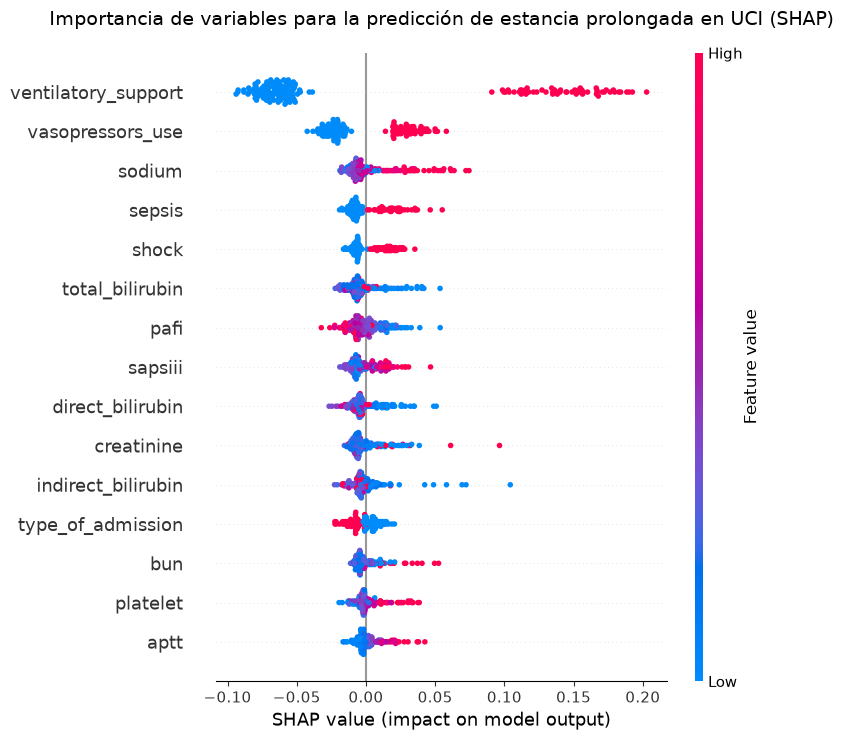

,importancia_media_absoluta_SHAP
ventilatory_support,0.091018
vasopressors_use,0.027054
sodium,0.013239
sepsis,0.011776
shock,0.010811
total_bilirubin,0.010138
pafi,0.009408
sapsiii,0.009027
direct_bilirubin,0.008917
creatinine,0.008849


In [287]:
# Excluir filas sin variable objetivo
mask_train = y_train_estancia.notna()
mask_test = y_test_estancia.notna()

X_train_estancia = x_train.loc[mask_train]
y_train_estancia_limpio = y_train_estancia.loc[mask_train]
X_test_estancia = x_test.loc[mask_test]

# Imputar y escalar: el ajuste se realiza solo con entrenamiento
prep_shap_estancia = Pipeline([
    ("knn", KNNImputer(n_neighbors=5)),
    ("media", SimpleImputer(strategy="mean")),
    ("escalado", StandardScaler()),
])

X_train_proc_estancia = prep_shap_estancia.fit_transform(X_train_estancia)
X_test_proc_estancia = prep_shap_estancia.transform(X_test_estancia)

try:
    nombres_variables_estancia = prep_shap_estancia.get_feature_names_out()
except Exception:
    nombres_variables_estancia = [
        f"variable_{i}" for i in range(X_train_proc_estancia.shape[1])
    ]

# Entrenar el modelo
rf_estancia_knn = RandomForestClassifier(random_state=0)
rf_estancia_knn.fit(X_train_proc_estancia, y_train_estancia_limpio)

# Seleccionar una muestra para calcular SHAP
n_muestra_estancia = min(500, X_test_proc_estancia.shape[0])
indices_estancia = np.random.default_rng(0).choice(
    X_test_proc_estancia.shape[0],
    size=n_muestra_estancia,
    replace=False
)
X_explicar_estancia = pd.DataFrame(
    X_test_proc_estancia[indices_estancia],
    columns=nombres_variables_estancia
)

# Calcular SHAP para la clase positiva
explainer_estancia = shap.TreeExplainer(rf_estancia_knn)
shap_resultado_estancia = explainer_estancia(X_explicar_estancia)
valores_shap_estancia = shap_resultado_estancia.values

indice_positivo = list(rf_estancia_knn.classes_).index(1)

if isinstance(valores_shap_estancia, list):
    valores_shap_positivos_estancia = valores_shap_estancia[indice_positivo]
elif valores_shap_estancia.ndim == 3:
    valores_shap_positivos_estancia = valores_shap_estancia[:, :, indice_positivo]
else:
    valores_shap_positivos_estancia = valores_shap_estancia

# Summary plot: 15 variables más importantes
shap.summary_plot(
    valores_shap_positivos_estancia,
    X_explicar_estancia,
    max_display=15,
    show=False
)

plt.title(
    "Importancia de variables para la predicción de estancia prolongada en UCI (SHAP)",
    fontsize=14,
    pad=20
)

plt.tight_layout()
plt.show()

# Ranking de importancia por media del valor absoluto de SHAP
importancias_shap_estancia = (
    pd.Series(
        np.abs(valores_shap_positivos_estancia).mean(axis=0),
        index=nombres_variables_estancia,
        name="importancia_media_absoluta_SHAP"
    )
    .sort_values(ascending=False)
    .head(15)
)

display(importancias_shap_estancia.to_frame())

In [255]:
importancias_shap_estancia.to_frame().to_excel(
    "H3_SHAP_estancia.xlsx",
    index=False)

# 6. Validación del rango de  las variables 

In [258]:
diccionario = pd.read_excel("../../anexos/C_diccionario_variables.xlsx",  sheet_name='diccionario')
df_api = diccionario[diccionario['variable'].isin(PREDICTORES)]

df_api

columnas_api = [ "variable", "descripcion", "unidad", "codificacion", "rango_plausible", "en_formulario_tablero", ]
df_api = df_api[columnas_api]
df_api

df_api.to_excel(
    "H5_rangos_API.xlsx",
    index=False
)

df_api

,variable,descripcion,unidad,codificacion,rango_plausible,en_formulario_tablero
1,sex,Sexo,-,"1 hombre, 2 mujer",1-2,NaN
2,age,Edad,años,continua,18-100,sí
3,bmi,Índice de masa corporal,kg/m²,continua,10-70,NaN
4,type_of_admission,Tipo de ingreso,-,"1 médico, 2 quirúrgico",1-2,sí
5,ecog,Estado funcional ECOG,-,0-4 (recodificado desde 1-5),0-4,sí
6,shock,Choque,-,"0 no, 1 sí",0-1,sí
7,sepsis,Sepsis,-,"0 no, 1 sí",0-1,sí
8,lactate,Lactato,mmol/L,continua,"0,1-30",sí
9,excess base,Exceso de base,mmol/L,continua,-30 a 30,NaN
10,bicarbonate,Bicarbonato,mmol/L,continua,2-50,NaN
